In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
# from kaggle_secrets import UserSecretsClient
# from huggingface_hub import login

# try:
#     token = UserSecretsClient().get_secret('HF_TOKEN')
#     login(token=token)
#     print('Hugging Face login: OK')
# except Exception as exc:
#     print('HF login was not completed automatically:', exc)
#     print('If the model is already cached and accessible, you can continue.')


# Google colab
from google.colab import userdata
from huggingface_hub import login

# Get token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')

# Login to Hugging Face
login(token=hf_token)


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [3]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""


'\n\nHint:\n# Analyze the weights of the query projection layer (q_proj) where layer = k\n q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()\n\n# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).\n U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)\n\n# Compute the retained energy ratio (Cumulative energy) of each singular value.\nenergy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100\n'


--- Analyzing Layer 0 ---
Minimum target rank for 50% cumulative energy: 62


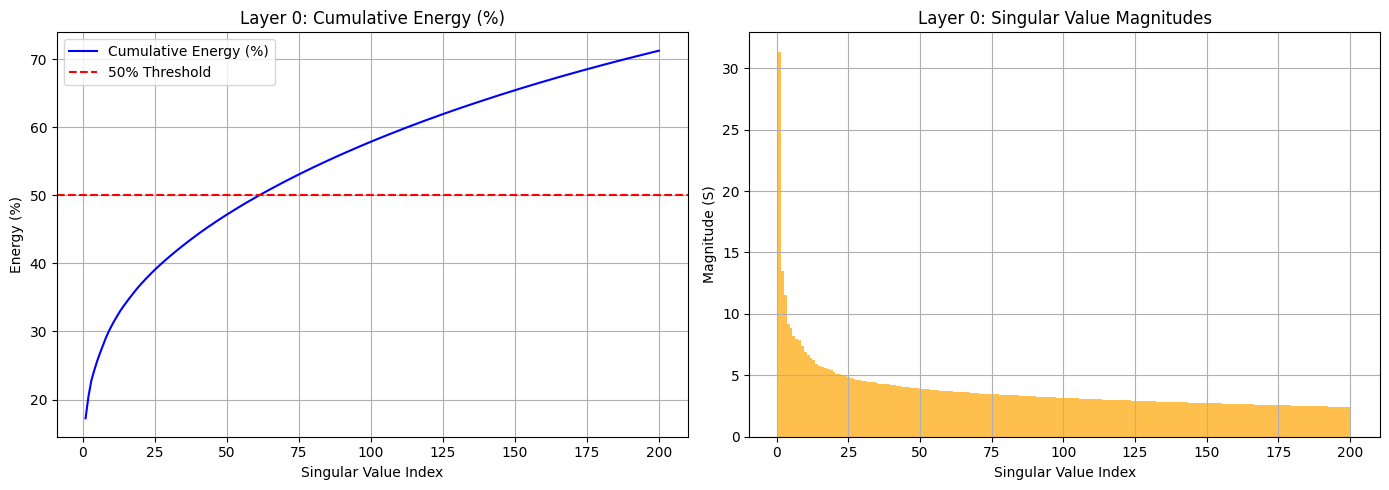


--- Analyzing Layer 7 ---
Minimum target rank for 50% cumulative energy: 120


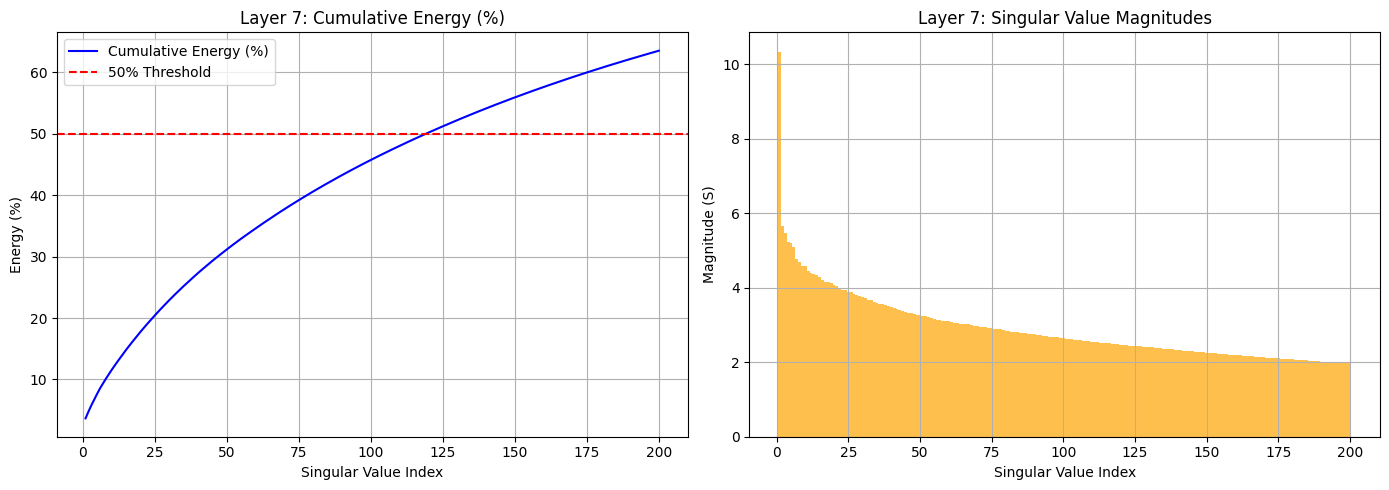


--- Analyzing Layer 15 ---
Minimum target rank for 50% cumulative energy: 84


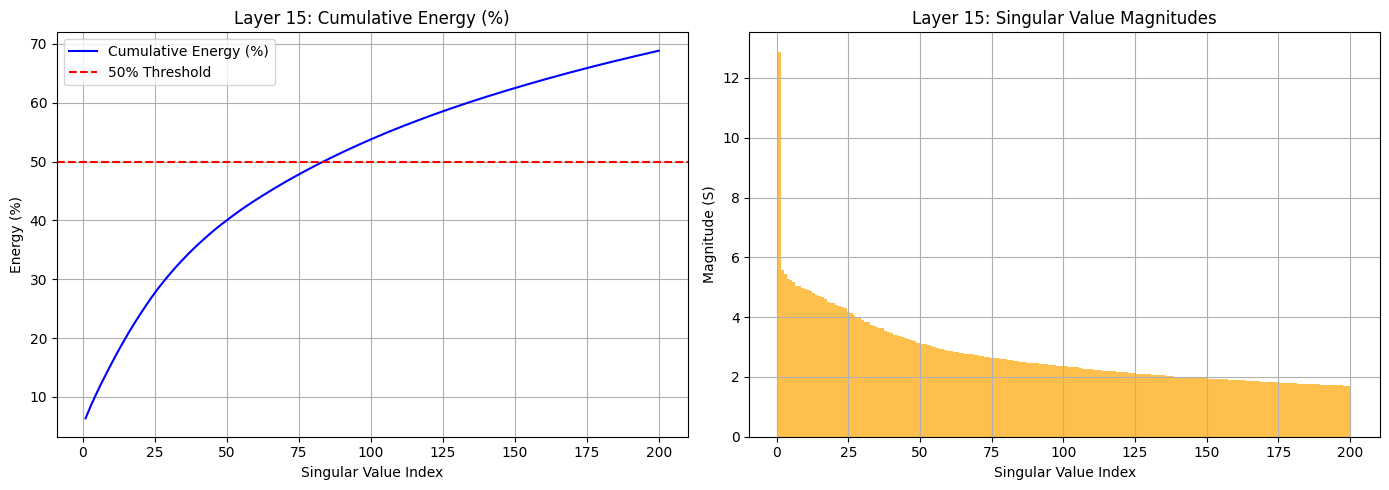

In [4]:
layers_to_check = [0, 7, 15]

for k in layers_to_check:
    print(f"\n--- Analyzing Layer {k} ---")

    # a. Extract weights from the query projection layer ("q_proj")
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

    # Apply Full SVD to decompose the weight matrix into U, S, and Vh
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

    # Compute the retained energy ratio (cumulative energy percentage)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # b. Find the minimum target rank required to retain at least 50% cumulative energy
    min_rank_50 = (energy_ratios >= 50).nonzero(as_tuple=True)[0][0].item() + 1
    print(f"Minimum target rank for 50% cumulative energy: {min_rank_50}")

    # c. Visualization (visualize only the first 200 singular values)
    S_vis = S[:200].cpu().numpy()
    energy_vis = energy_ratios[:200].cpu().numpy()
    x_axis = range(1, len(S_vis) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # i. Line chart for Cumulative Energy (%)
    axes[0].plot(x_axis, energy_vis, color='b', label='Cumulative Energy (%)')
    axes[0].axhline(y=50, color='r', linestyle='--', label='50% Threshold')
    axes[0].set_title(f'Layer {k}: Cumulative Energy (%)')
    axes[0].set_xlabel('Singular Value Index')
    axes[0].set_ylabel('Energy (%)')
    axes[0].legend()
    axes[0].grid(True)

    # ii. Bar chart for Singular Value Magnitudes
    axes[1].bar(x_axis, S_vis, color='orange', alpha=0.7, width=1.0)
    axes[1].set_title(f'Layer {k}: Singular Value Magnitudes')
    axes[1].set_xlabel('Singular Value Index')
    axes[1].set_ylabel('Magnitude (S)')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()